# Taller de clasificación con árboles de decisión

**Autor:** Camilo Andrés Díaz García
**Asignatura:** Inteligencia Artificial, Universidad Sergio Arboleda,
Bogotá, 2026-2

El cuaderno resuelve el taller completo. La primera parte (secciones 1 a 4)
reproduce el cálculo manual con el índice Gini sobre la tabla sintética de
12 diamantes y las métricas de evaluación. La segunda parte (sección 5)
verifica el cálculo con `scikit-learn` y ejecuta el experimento con Iris,
separando entrenamiento, validación y prueba. Los datos sintéticos están
escritos dentro del cuaderno, e Iris se carga con `scikit-learn`, por lo que
no se necesita descargar ningún archivo.

In [1]:
import os
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from sklearn.datasets import load_iris
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEMILLA = 42
CARPETA = "resultados"
os.makedirs(CARPETA, exist_ok=True)

COLOR = {"A": "#0072B2", "E": "#D55E00"}
TINTE = {"A": "#CFE3F2", "E": "#F6D9C8"}
MARCA = {"A": "o", "E": "s"}
GRIS = "#6B6B6B"

plt.rcParams.update({
    "font.size": 11,
    "axes.grid.axis": "y",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#E3E3E3",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "figure.dpi": 100,
})


def num(x, decimales=4):
    """Formatea un número con coma decimal."""
    return f"{x:.{decimales}f}".replace(".", ",")


def coma(ax, eje="both"):
    """Muestra los ticks de los ejes con coma decimal."""
    formato = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
    if eje in ("x", "both"):
        ax.xaxis.set_major_formatter(formato)
    if eje in ("y", "both"):
        ax.yaxis.set_major_formatter(formato)


def mostrar(tabla, decimales=4):
    """Imprime una tabla con coma decimal en las columnas numéricas."""
    copia = tabla.copy()
    for col in copia.columns:
        if pd.api.types.is_float_dtype(copia[col]):
            copia[col] = copia[col].map(lambda v: num(v, decimales))
    print(copia.to_string(index=False))


def colorear_arbol(anotaciones, tintes):
    """Pinta cada nodo de plot_tree con el color de su clase."""
    for nota in anotaciones:
        ultima = nota.get_text().splitlines()[-1]
        if nota.get_bbox_patch() is not None and ultima.startswith("class"):
            nota.get_bbox_patch().set_facecolor(
                tintes[ultima.replace("class = ", "")])


def guardar(nombre):
    """Guarda la figura actual en la carpeta de resultados y la muestra."""
    plt.savefig(os.path.join(CARPETA, nombre), dpi=200,
                bbox_inches="tight")
    plt.show()

## 1. Formulación del problema

- **Unidad de observación:** un diamante.
- **Características X:** quilates y profundidad (%).
- **Etiqueta y:** clase del corte, con dos valores posibles: aceptable (A)
  o excelente (E).
- **Tipo de problema:** aprendizaje supervisado de clasificación, porque
  cada ejemplo trae la respuesta correcta y la salida es una categoría.
- El `ID` es solo un identificador y no se usa como predictor.

In [2]:
datos = pd.DataFrame({
    "ID": range(1, 13),
    "quilates": [0.30, 0.40, 0.50, 0.60, 0.70, 0.80,
                 0.90, 1.00, 1.10, 1.20, 1.30, 1.40],
    "profundidad": [60, 61, 64, 62, 65, 63, 61, 64, 62, 65, 60, 63],
    "clase": list("AAAEAEEAEAEE"),
})
mostrar(datos, 2)
print()
print("Conteo por clase:")
print(datos["clase"].value_counts().sort_index().to_string())

 ID quilates  profundidad clase
  1     0,30           60     A
  2     0,40           61     A
  3     0,50           64     A
  4     0,60           62     E
  5     0,70           65     A
  6     0,80           63     E
  7     0,90           61     E
  8     1,00           64     A
  9     1,10           62     E
 10     1,20           65     A
 11     1,30           60     E
 12     1,40           63     E

Conteo por clase:
clase
A    6
E    6


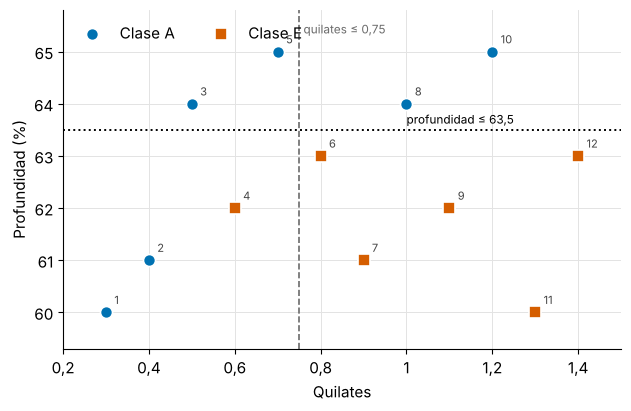

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for clase in ["A", "E"]:
    sub = datos[datos["clase"] == clase]
    ax.scatter(sub["quilates"], sub["profundidad"], s=75, c=COLOR[clase],
               marker=MARCA[clase], edgecolor="white", linewidth=1.2,
               label=f"Clase {clase}", zorder=3)
for _, fila in datos.iterrows():
    ax.annotate(str(int(fila["ID"])), (fila["quilates"], fila["profundidad"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8,
                color="#444444")
ax.axvline(0.75, color=GRIS, linestyle="--", linewidth=1.2)
ax.axhline(63.5, color="#000000", linestyle=":", linewidth=1.4)
ax.text(0.76, 65.35, "quilates ≤ 0,75", color=GRIS, fontsize=8.5)
ax.text(1.0, 63.62, "profundidad ≤ 63,5", color="#000000", fontsize=8.5)
ax.set_xlabel("Quilates")
ax.set_ylabel("Profundidad (%)")
ax.set_xlim(0.2, 1.5)
ax.set_ylim(59.3, 65.8)
ax.grid(True, axis="both")
coma(ax)
ax.legend(loc="upper left", frameon=False, ncol=2)
guardar("fig_01_datos_candidatas.png")

## 2. Selección de la raíz con el índice Gini

Para un nodo $S$ con $K$ clases,
$G(S) = 1 - \sum_{k=1}^{K} p_k^2$, la impureza ponderada de una división es
$G_{div} = \frac{|S_L|}{|S|} G(S_L) + \frac{|S_R|}{|S|} G(S_R)$ y la
reducción es $\Delta G = G(S) - G_{div}$. A la izquierda van los casos con
$x \leq t$ y a la derecha los casos con $x > t$.

In [4]:
def gini(etiquetas):
    """Impureza Gini de un conjunto de etiquetas."""
    etiquetas = pd.Series(list(etiquetas))
    if len(etiquetas) == 0:
        return 0.0
    proporciones = etiquetas.value_counts() / len(etiquetas)
    return float(1.0 - (proporciones ** 2).sum())


def conteo(df):
    """Devuelve el número de casos A y E de un nodo."""
    return int((df["clase"] == "A").sum()), int((df["clase"] == "E").sum())


def evaluar_division(df, variable, umbral):
    """Evalúa la pregunta variable <= umbral dentro del nodo df."""
    izq = df[df[variable] <= umbral]
    der = df[df[variable] > umbral]
    g_izq, g_der = gini(izq["clase"]), gini(der["clase"])
    g_div = len(izq) / len(df) * g_izq + len(der) / len(df) * g_der
    a_izq, e_izq = conteo(izq)
    a_der, e_der = conteo(der)
    return {
        "variable": variable, "umbral": umbral,
        "n_izq": len(izq), "a_izq": a_izq, "e_izq": e_izq,
        "g_izq": g_izq, "ids_izq": list(izq["ID"]),
        "n_der": len(der), "a_der": a_der, "e_der": e_der,
        "g_der": g_der, "ids_der": list(der["ID"]),
        "g_div": g_div, "delta": gini(df["clase"]) - g_div,
    }


def puntos_medios(df, variable):
    """Umbrales: puntos medios entre valores consecutivos distintos."""
    valores = np.sort(df[variable].unique())
    return np.round((valores[:-1] + valores[1:]) / 2, 6)

In [5]:
a_raiz, e_raiz = conteo(datos)
g_raiz = gini(datos["clase"])
print(f"Ejemplos A: {a_raiz}, ejemplos E: {e_raiz}, total: {len(datos)}")
print(f"G(raíz) = 1 - (({a_raiz}/12)^2 + ({e_raiz}/12)^2) = "
      f"{num(g_raiz)}")

Ejemplos A: 6, ejemplos E: 6, total: 12
G(raíz) = 1 - ((6/12)^2 + (6/12)^2) = 0,5000


In [6]:
candidatas = [("quilates", 0.75), ("profundidad", 63.5)]
resultados_div = [evaluar_division(datos, v, t) for v, t in candidatas]

filas = []
for r in resultados_div:
    decimales = 2 if r["variable"] == "quilates" else 1
    filas.append({
        "pregunta": f"{r['variable']} ≤ {num(r['umbral'], decimales)}",
        "nL": r["n_izq"], "A/E en SL": f"{r['a_izq']}/{r['e_izq']}",
        "G(SL)": r["g_izq"], "nR": r["n_der"],
        "A/E en SR": f"{r['a_der']}/{r['e_der']}", "G(SR)": r["g_der"],
        "Gdiv": r["g_div"], "ΔG": r["delta"],
    })
    print(f"{filas[-1]['pregunta']}: ID izquierda = {r['ids_izq']}, "
          f"ID derecha = {r['ids_der']}")
tabla_raiz = pd.DataFrame(filas)
print()
mostrar(tabla_raiz)

mejor = max(resultados_div, key=lambda r: r["delta"])
print(f"\nRaíz elegida entre las dos candidatas: {mejor['variable']} ≤ "
      f"{num(mejor['umbral'], 1)}")

quilates ≤ 0,75: ID izquierda = [1, 2, 3, 4, 5], ID derecha = [6, 7, 8, 9, 10, 11, 12]
profundidad ≤ 63,5: ID izquierda = [1, 2, 4, 6, 7, 9, 11, 12], ID derecha = [3, 5, 8, 10]

          pregunta  nL A/E en SL  G(SL)  nR A/E en SR  G(SR)   Gdiv     ΔG
   quilates ≤ 0,75   5       4/1 0,3200   7       2/5 0,4082 0,3714 0,1286
profundidad ≤ 63,5   8       2/6 0,3750   4       4/0 0,0000 0,2500 0,2500

Raíz elegida entre las dos candidatas: profundidad ≤ 63,5


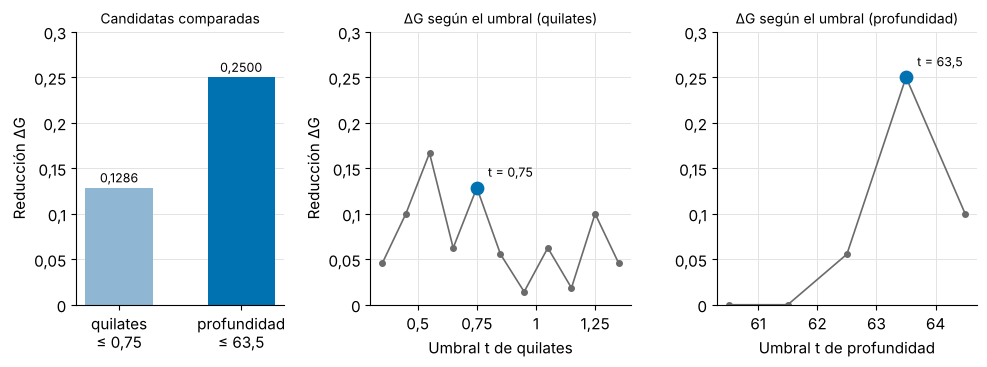

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.8),
                         gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
ax = ejes[0]
etiquetas = ["quilates\n≤ 0,75", "profundidad\n≤ 63,5"]
valores = [r["delta"] for r in resultados_div]
barras = ax.bar(etiquetas, valores, color=["#8FB6D3", COLOR["A"]],
                width=0.55)
for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.006,
            num(valor), ha="center", fontsize=9)
ax.set_ylabel("Reducción ΔG")
ax.set_ylim(0, 0.30)
coma(ax, "y")
ax.set_title("Candidatas comparadas", fontsize=10)

for ax, variable, elegido in zip(ejes[1:], ["quilates", "profundidad"],
                                 [0.75, 63.5]):
    umbrales = puntos_medios(datos, variable)
    deltas = [evaluar_division(datos, variable, u)["delta"]
              for u in umbrales]
    ax.plot(umbrales, deltas, "o-", color=GRIS, markersize=4,
            linewidth=1.2)
    d_elegido = evaluar_division(datos, variable, elegido)["delta"]
    ax.scatter([elegido], [d_elegido], s=80, color=COLOR["A"], zorder=4)
    ax.annotate(f"t = {num(elegido, 2 if variable == 'quilates' else 1)}",
                (elegido, d_elegido), textcoords="offset points",
                xytext=(8, 8), fontsize=9)
    ax.set_xlabel(f"Umbral t de {variable}")
    ax.set_ylim(0, 0.30)
    ax.grid(True, axis="both")
    coma(ax)
    ax.set_title(f"ΔG según el umbral ({variable})", fontsize=10)
ejes[1].set_ylabel("Reducción ΔG")
plt.tight_layout()
guardar("fig_02_comparacion_gini.png")

La comparación pedida se limita a las dos preguntas candidatas. La curva
de $\Delta G$ sobre todos los puntos medios se incluye solo como contexto y
no reemplaza la justificación de la raíz.

## 3. Construcción e interpretación del árbol

La raíz elegida es `profundidad ≤ 63,5`. Su hijo derecho es puro (4 casos A)
y el hijo izquierdo tiene 8 casos mezclados, por lo que se busca una
división adicional solo en ese nodo.

In [8]:
izquierdo = datos[datos["profundidad"] <= 63.5]
derecho = datos[datos["profundidad"] > 63.5]
print("Hijo izquierdo (IDs):", list(izquierdo["ID"]),
      "A/E =", conteo(izquierdo), "G =", num(gini(izquierdo["clase"])))
print("Hijo derecho (IDs):", list(derecho["ID"]),
      "A/E =", conteo(derecho), "G =", num(gini(derecho["clase"])))

for variable in ["quilates", "profundidad"]:
    ordenados = sorted(izquierdo[variable].unique())
    print(f"\n{variable} ordenado:",
          ", ".join(num(v, 2) for v in ordenados))
    print("Puntos medios:",
          ", ".join(num(v, 3) for v in puntos_medios(izquierdo, variable)))

Hijo izquierdo (IDs): [1, 2, 4, 6, 7, 9, 11, 12] A/E = (2, 6) G = 0,3750
Hijo derecho (IDs): [3, 5, 8, 10] A/E = (4, 0) G = 0,0000

quilates ordenado: 0,30, 0,40, 0,60, 0,80, 0,90, 1,10, 1,30, 1,40
Puntos medios: 0,350, 0,500, 0,700, 0,850, 1,000, 1,200, 1,350

profundidad ordenado: 60,00, 61,00, 62,00, 63,00
Puntos medios: 60,500, 61,500, 62,500


In [9]:
filas = []
for variable in ["quilates", "profundidad"]:
    for t in puntos_medios(izquierdo, variable):
        r = evaluar_division(izquierdo, variable, float(t))
        filas.append({
            "pregunta": f"{variable} ≤ {num(r['umbral'], 3)}",
            "nL": r["n_izq"], "A/E en SL": f"{r['a_izq']}/{r['e_izq']}",
            "G(SL)": r["g_izq"], "nR": r["n_der"],
            "A/E en SR": f"{r['a_der']}/{r['e_der']}",
            "G(SR)": r["g_der"], "Gdiv": r["g_div"], "ΔG": r["delta"],
        })
tabla_hijo = pd.DataFrame(filas)
mostrar(tabla_hijo)
mejor_hijo = tabla_hijo.loc[tabla_hijo["ΔG"].idxmax()]
print("\nMejor división adicional:", mejor_hijo["pregunta"],
      "con ΔG =", num(mejor_hijo["ΔG"]))

            pregunta  nL A/E en SL  G(SL)  nR A/E en SR  G(SR)   Gdiv     ΔG
    quilates ≤ 0,350   1       1/0 0,0000   7       1/6 0,2449 0,2143 0,1607
    quilates ≤ 0,500   2       2/0 0,0000   6       0/6 0,0000 0,0000 0,3750
    quilates ≤ 0,700   3       2/1 0,4444   5       0/5 0,0000 0,1667 0,2083
    quilates ≤ 0,850   4       2/2 0,5000   4       0/4 0,0000 0,2500 0,1250
    quilates ≤ 1,000   5       2/3 0,4800   3       0/3 0,0000 0,3000 0,0750
    quilates ≤ 1,200   6       2/4 0,4444   2       0/2 0,0000 0,3333 0,0417
    quilates ≤ 1,350   7       2/5 0,4082   1       0/1 0,0000 0,3571 0,0179
profundidad ≤ 60,500   2       1/1 0,5000   6       1/5 0,2778 0,3333 0,0417
profundidad ≤ 61,500   4       2/2 0,5000   4       0/4 0,0000 0,2500 0,1250
profundidad ≤ 62,500   6       2/4 0,4444   2       0/2 0,0000 0,3333 0,0417

Mejor división adicional: quilates ≤ 0,500 con ΔG = 0,3750


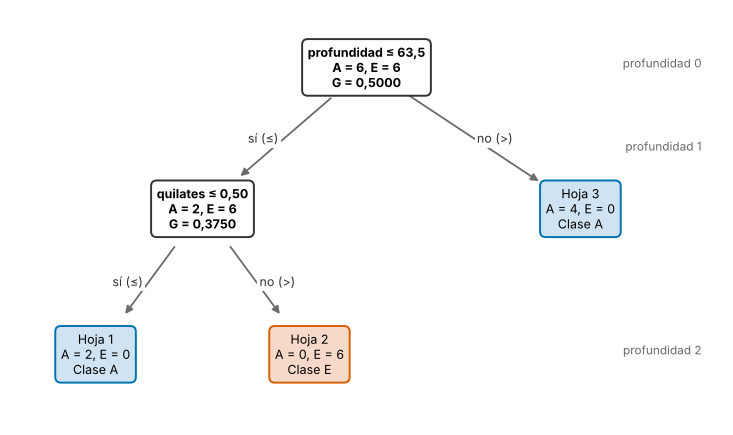

In [10]:
def dibujar_nodo(ax, xy, texto, relleno, borde, negrita=False):
    ax.text(xy[0], xy[1], texto, ha="center", va="center", fontsize=9,
            fontweight="bold" if negrita else "normal",
            bbox=dict(boxstyle="round,pad=0.45", fc=relleno, ec=borde,
                      lw=1.4), zorder=3)


def dibujar_flecha(ax, origen, destino, etiqueta, desplazamiento):
    ax.annotate("", xy=destino, xytext=origen,
                arrowprops=dict(arrowstyle="-|>", color=GRIS, lw=1.3,
                                shrinkA=34, shrinkB=36), zorder=1)
    medio = ((origen[0] + destino[0]) / 2 + desplazamiento,
             (origen[1] + destino[1]) / 2)
    ax.text(medio[0], medio[1], etiqueta, fontsize=9, color="#333333",
            ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=1.5))


def texto_nodo(pregunta, df):
    a, e = conteo(df)
    return f"{pregunta}\nA = {a}, E = {e}\nG = {num(gini(df['clase']))}"


def clase_hoja(df):
    a, e = conteo(df)
    return "A" if a >= e else "E"


def texto_hoja(numero, df):
    a, e = conteo(df)
    return (f"Hoja {numero}\nA = {a}, E = {e}\n"
            f"Clase {clase_hoja(df)}")


h1 = izquierdo[izquierdo["quilates"] <= 0.50]
h2 = izquierdo[izquierdo["quilates"] > 0.50]
fig, ax = plt.subplots(figsize=(9.2, 5.4))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
raiz_xy, izq_xy, der_xy = (0.5, 0.86), (0.27, 0.52), (0.80, 0.52)
h1_xy, h2_xy = (0.12, 0.17), (0.42, 0.17)
dibujar_nodo(ax, raiz_xy, texto_nodo("profundidad ≤ 63,5", datos),
             "#FFFFFF", "#333333", True)
dibujar_nodo(ax, izq_xy, texto_nodo("quilates ≤ 0,50", izquierdo),
             "#FFFFFF", "#333333", True)
dibujar_nodo(ax, der_xy, texto_hoja(3, derecho), TINTE["A"], COLOR["A"])
dibujar_nodo(ax, h1_xy, texto_hoja(1, h1), TINTE[clase_hoja(h1)],
             COLOR[clase_hoja(h1)])
dibujar_nodo(ax, h2_xy, texto_hoja(2, h2), TINTE[clase_hoja(h2)],
             COLOR[clase_hoja(h2)])
dibujar_flecha(ax, raiz_xy, izq_xy, "sí (≤)", -0.03)
dibujar_flecha(ax, raiz_xy, der_xy, "no (>)", 0.03)
dibujar_flecha(ax, izq_xy, h1_xy, "sí (≤)", -0.03)
dibujar_flecha(ax, izq_xy, h2_xy, "no (>)", 0.03)
ax.text(0.97, 0.86, "profundidad 0", fontsize=8.5, color=GRIS, ha="right")
ax.text(0.97, 0.66, "profundidad 1", fontsize=8.5, color=GRIS, ha="right")
ax.text(0.97, 0.17, "profundidad 2", fontsize=8.5, color=GRIS, ha="right")
guardar("fig_03_arbol_manual.png")

In [11]:
def clasificar_manual(quilates, profundidad):
    """Aplica las tres reglas del árbol manual y reporta el recorrido."""
    if profundidad <= 63.5:
        if quilates <= 0.50:
            return "A", "H1", "profundidad ≤ 63,5 (sí) → quilates ≤ 0,50 (sí)"
        return "E", "H2", "profundidad ≤ 63,5 (sí) → quilates ≤ 0,50 (no)"
    return "A", "H3", "profundidad ≤ 63,5 (no)"


nuevos = pd.DataFrame({
    "caso": ["N1", "N2", "N3", "N4"],
    "quilates": [0.45, 1.15, 0.85, 0.55],
    "profundidad": [62.0, 64.0, 61.0, 63.5],
})
salidas = [clasificar_manual(q, p)
           for q, p in zip(nuevos["quilates"], nuevos["profundidad"])]
nuevos["clase_manual"] = [s[0] for s in salidas]
nuevos["hoja"] = [s[1] for s in salidas]
nuevos["recorrido"] = [s[2] for s in salidas]
mostrar(nuevos, 2)

pred_filas = [clasificar_manual(q, p)[0]
              for q, p in zip(datos["quilates"], datos["profundidad"])]
exactitud_12 = np.mean(np.array(pred_filas) == datos["clase"].to_numpy())
print(f"\nExactitud del árbol manual sobre las 12 filas: "
      f"{num(exactitud_12, 2)}")

caso quilates profundidad clase_manual hoja                                      recorrido
  N1     0,45       62,00            A   H1 profundidad ≤ 63,5 (sí) → quilates ≤ 0,50 (sí)
  N2     1,15       64,00            A   H3                        profundidad ≤ 63,5 (no)
  N3     0,85       61,00            E   H2 profundidad ≤ 63,5 (sí) → quilates ≤ 0,50 (no)
  N4     0,55       63,50            E   H2 profundidad ≤ 63,5 (sí) → quilates ≤ 0,50 (no)

Exactitud del árbol manual sobre las 12 filas: 1,00


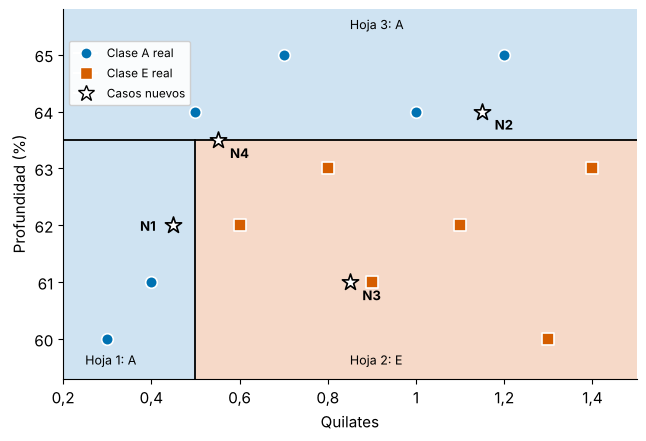

In [12]:
malla_q = np.linspace(0.2, 1.5, 300)
malla_p = np.linspace(59.3, 65.8, 300)
zq, zp = np.meshgrid(malla_q, malla_p)
codigo = np.vectorize(
    lambda q, p: 0 if clasificar_manual(q, p)[0] == "A" else 1)(zq, zp)

fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.contourf(zq, zp, codigo, levels=[-0.5, 0.5, 1.5],
            colors=[TINTE["A"], TINTE["E"]], zorder=0)
ax.grid(False)
ax.axhline(63.5, color="#000000", linewidth=1.3)
ax.plot([0.5, 0.5], [59.3, 63.5], color="#000000", linewidth=1.3)
for clase in ["A", "E"]:
    sub = datos[datos["clase"] == clase]
    ax.scatter(sub["quilates"], sub["profundidad"], s=70, c=COLOR[clase],
               marker=MARCA[clase], edgecolor="white", linewidth=1.2,
               zorder=3)
for _, fila in nuevos.iterrows():
    ax.scatter(fila["quilates"], fila["profundidad"], s=150,
               marker="*", c="#FFFFFF", edgecolor="#000000", linewidth=1.2,
               zorder=4)
    desplazamiento = (-24, -4) if fila["caso"] == "N1" else (9, -13)
    ax.annotate(fila["caso"], (fila["quilates"], fila["profundidad"]),
                textcoords="offset points", xytext=desplazamiento,
                fontsize=9.5, fontweight="bold")
ax.text(0.25, 59.55, "Hoja 1: A", fontsize=9)
ax.text(0.85, 59.55, "Hoja 2: E", fontsize=9)
ax.text(0.85, 65.45, "Hoja 3: A", fontsize=9)
ax.set_xlabel("Quilates")
ax.set_ylabel("Profundidad (%)")
ax.set_xlim(0.2, 1.5)
ax.set_ylim(59.3, 65.8)
coma(ax)
leyenda = [
    Line2D([], [], marker="o", color="w", markerfacecolor=COLOR["A"],
           markersize=8, label="Clase A real"),
    Line2D([], [], marker="s", color="w", markerfacecolor=COLOR["E"],
           markersize=8, label="Clase E real"),
    Line2D([], [], marker="*", color="w", markerfacecolor="#FFFFFF",
           markeredgecolor="#000000", markersize=12,
           label="Casos nuevos"),
]
ax.legend(handles=leyenda, loc="upper left", frameon=True, fontsize=8.5,
          bbox_to_anchor=(0.0, 0.93), framealpha=0.9)
guardar("fig_04_mapa_decision.png")

## 4. Evaluación de las predicciones

Con A como clase positiva, la matriz hipotética de 20 casos tiene
$VP = 6$, $FN = 2$, $FP = 3$ y $VN = 9$.

In [13]:
def metricas_binarias(vp, fn, fp, vn):
    n = vp + fn + fp + vn
    return {
        "exactitud": (vp + vn) / n,
        "precisión": vp / (vp + fp),
        "recall": vp / (vp + fn),
        "F1": 2 * vp / (2 * vp + fp + fn),
    }


VP, FN, FP, VN = 6, 2, 3, 9
metricas = metricas_binarias(VP, FN, FP, VN)
print(f"VP = {VP}, FN = {FN}, FP = {FP}, VN = {VN}, N = 20")
print(f"Exactitud = ({VP}+{VN})/20 = {num(metricas['exactitud'])}")
print(f"Precisión = {VP}/({VP}+{FP}) = {num(metricas['precisión'])}")
print(f"Recall    = {VP}/({VP}+{FN}) = {num(metricas['recall'])}")
print(f"F1        = 2·{VP}/(2·{VP}+{FP}+{FN}) = {num(metricas['F1'])}")

VP = 6, FN = 2, FP = 3, VN = 9, N = 20
Exactitud = (6+9)/20 = 0,7500
Precisión = 6/(6+3) = 0,6667
Recall    = 6/(6+2) = 0,7500
F1        = 2·6/(2·6+3+2) = 0,7059


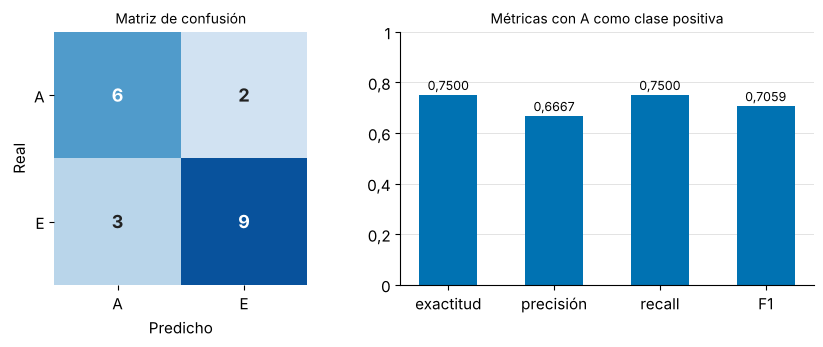

In [14]:
def matriz_calor(ax, matriz, etiquetas, titulo):
    ax.imshow(matriz, cmap="Blues", vmin=0, vmax=matriz.max() * 1.15)
    ax.grid(False)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            claro = matriz[i, j] > matriz.max() * 0.55
            ax.text(j, i, str(matriz[i, j]), ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if claro else "#222222")
    ax.set_xticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas)
    ax.set_yticks(range(len(etiquetas)))
    ax.set_yticklabels(etiquetas)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(titulo, fontsize=10)
    for lado in ax.spines.values():
        lado.set_visible(False)


matriz_hip = np.array([[VP, FN], [FP, VN]])
fig, ejes = plt.subplots(1, 2, figsize=(8.8, 3.6),
                         gridspec_kw={"width_ratios": [1, 1.2]})
matriz_calor(ejes[0], matriz_hip, ["A", "E"], "Matriz de confusión")
nombres = list(metricas.keys())
valores = [metricas[k] for k in nombres]
barras = ejes[1].bar(nombres, valores, color=COLOR["A"], width=0.55)
for barra, valor in zip(barras, valores):
    ejes[1].text(barra.get_x() + barra.get_width() / 2, valor + 0.02,
                 num(valor), ha="center", fontsize=9)
ejes[1].set_ylim(0, 1.0)
ejes[1].set_title("Métricas con A como clase positiva", fontsize=10)
coma(ejes[1], "y")
plt.tight_layout()
guardar("fig_05_metricas_hipoteticas.png")

Exactitud = 95/100 = 0,95
Recall de A = 1,00, recall de E = 0,00


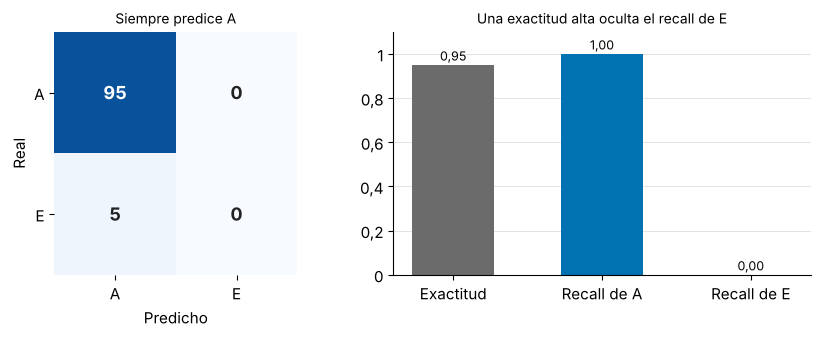

In [15]:
# Clasificador que siempre predice A en 95 ejemplos A y 5 ejemplos E.
vp2, fn2, fp2, vn2 = 95, 0, 5, 0
exactitud_dummy = (vp2 + vn2) / 100
recall_A = vp2 / (vp2 + fn2)
recall_E = vn2 / (vn2 + fp2)
print(f"Exactitud = 95/100 = {num(exactitud_dummy, 2)}")
print(f"Recall de A = {num(recall_A, 2)}, recall de E = {num(recall_E, 2)}")

fig, ejes = plt.subplots(1, 2, figsize=(8.8, 3.5),
                         gridspec_kw={"width_ratios": [1, 1.2]})
matriz_calor(ejes[0], np.array([[95, 0], [5, 0]]), ["A", "E"],
             "Siempre predice A")
nombres = ["Exactitud", "Recall de A", "Recall de E"]
valores = [exactitud_dummy, recall_A, recall_E]
colores = [GRIS, COLOR["A"], COLOR["E"]]
barras = ejes[1].bar(nombres, valores, color=colores, width=0.55)
for barra, valor in zip(barras, valores):
    ejes[1].text(barra.get_x() + barra.get_width() / 2, valor + 0.02,
                 num(valor, 2), ha="center", fontsize=9)
ejes[1].set_ylim(0, 1.1)
ejes[1].set_title("Una exactitud alta oculta el recall de E", fontsize=10)
coma(ejes[1], "y")
plt.tight_layout()
guardar("fig_06_clase_mayoritaria.png")

## 5. Implementación y generalización en Python

### Parte A. Verificación del cálculo manual

In [16]:
X_sint = datos[["quilates", "profundidad"]]
y_sint = datos["clase"]
arbol_sint = DecisionTreeClassifier(criterion="gini", max_depth=2,
                                    random_state=SEMILLA)
arbol_sint.fit(X_sint, y_sint)
print(export_text(arbol_sint, feature_names=list(X_sint.columns)))
print("Profundidad:", arbol_sint.get_depth(), "| Hojas:",
      arbol_sint.get_n_leaves())
print("Exactitud sobre las 12 filas de ajuste:",
      num(arbol_sint.score(X_sint, y_sint), 2))

|--- profundidad <= 63.50
|   |--- quilates <= 0.50
|   |   |--- class: A
|   |--- quilates >  0.50
|   |   |--- class: E
|--- profundidad >  63.50
|   |--- class: A

Profundidad: 2 | Hojas: 3
Exactitud sobre las 12 filas de ajuste: 1,00


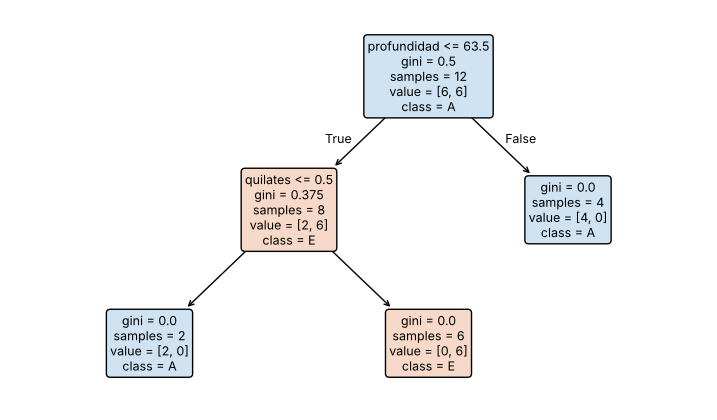

In [17]:
fig, ax = plt.subplots(figsize=(9, 5.2))
notas = plot_tree(arbol_sint, feature_names=["quilates", "profundidad"],
                  class_names=list(arbol_sint.classes_), filled=True,
                  rounded=True, impurity=True, fontsize=9, ax=ax)
colorear_arbol(notas, TINTE)
guardar("fig_07_plot_tree_sintetico.png")

In [18]:
pred_sk = arbol_sint.predict(nuevos[["quilates", "profundidad"]])
comparacion = pd.DataFrame({
    "caso": nuevos["caso"],
    "manual": nuevos["clase_manual"],
    "scikit-learn": pred_sk,
})
comparacion["coincide"] = np.where(
    comparacion["manual"] == comparacion["scikit-learn"], "sí", "no")
print(comparacion.to_string(index=False))

caso manual scikit-learn coincide
  N1      A            A       sí
  N2      A            A       sí
  N3      E            E       sí
  N4      E            E       sí


### Parte B. Experimento con Iris

En esta parte el problema es multiclase, por lo que A deja de ser la clase
positiva. Las medidas están en centímetros.

In [19]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
nombres_clase = [str(n) for n in iris.target_names]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEMILLA
)

print("Predictores:", list(iris.feature_names))
print("Clases:", nombres_clase)
particiones = pd.DataFrame({
    "partición": ["entrenamiento", "validación", "prueba"],
    "casos": [len(y_train), len(y_val), len(y_test)],
    **{c: [int((p == i).sum()) for p in (y_train, y_val, y_test)]
       for i, c in enumerate(nombres_clase)},
})
print()
print(particiones.to_string(index=False))

Predictores: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa', 'versicolor', 'virginica']

    partición  casos  setosa  versicolor  virginica
entrenamiento     90      30          30         30
   validación     30      10          10         10
       prueba     30      10          10         10


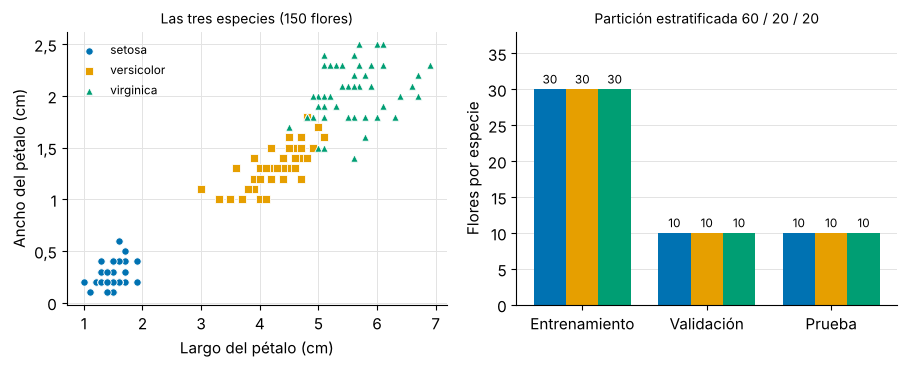

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.8))
paleta = ["#0072B2", "#E69F00", "#009E73"]
marcas = ["o", "s", "^"]
ax = ejes[0]
for i, c in enumerate(nombres_clase):
    sub = X[y == i]
    ax.scatter(sub["petal length (cm)"], sub["petal width (cm)"], s=28,
               c=paleta[i], marker=marcas[i], edgecolor="white",
               linewidth=0.6, label=c)
ax.set_xlabel("Largo del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Las tres especies (150 flores)", fontsize=10)
ax.grid(True, axis="both")
coma(ax)
ax = ejes[1]
base = np.arange(3)
ancho = 0.26
for i, c in enumerate(nombres_clase):
    cuentas = [int((p == i).sum()) for p in (y_train, y_val, y_test)]
    ax.bar(base + (i - 1) * ancho, cuentas, ancho, color=paleta[i], label=c)
    for x0, cuenta in zip(base + (i - 1) * ancho, cuentas):
        ax.text(x0, cuenta + 0.8, str(cuenta), ha="center", fontsize=8.5)
ax.set_xticks(base)
ax.set_xticklabels(["Entrenamiento", "Validación", "Prueba"])
ax.set_ylabel("Flores por especie")
ax.set_ylim(0, 38)
ax.set_title("Partición estratificada 60 / 20 / 20", fontsize=10)
plt.tight_layout()
guardar("fig_08_iris_particiones.png")

In [21]:
candidatos = [1, 3, None]
modelos = {}
filas = []
for orden, profundidad in enumerate(candidatos):
    modelo = DecisionTreeClassifier(criterion="gini",
                                    max_depth=profundidad,
                                    random_state=SEMILLA)
    modelo.fit(X_train, y_train)
    pred_val = modelo.predict(X_val)
    etiqueta = "sin límite" if profundidad is None else str(profundidad)
    modelos[etiqueta] = modelo
    filas.append({
        "profundidad máxima": etiqueta,
        "exactitud entrenamiento": accuracy_score(y_train,
                                                  modelo.predict(X_train)),
        "exactitud validación": accuracy_score(y_val, pred_val),
        "F1 macro validación": f1_score(y_val, pred_val, average="macro"),
        "profundidad efectiva": modelo.get_depth(),
        "hojas": modelo.get_n_leaves(),
        "orden": orden,
    })
tabla_modelos = pd.DataFrame(filas)
mostrar(tabla_modelos.drop(columns="orden"))

profundidad máxima exactitud entrenamiento exactitud validación F1 macro validación  profundidad efectiva  hojas
                 1                  0,6667               0,6667              0,5556                     1      2
                 3                  0,9889               0,9000              0,8997                     3      4
        sin límite                  1,0000               0,9333              0,9333                     4      5


In [22]:
# Regla de selección: mayor F1 macro de validación; en empate, menor
# profundidad efectiva, luego menos hojas y luego el orden 1, 3, sin límite.
clave = tabla_modelos.assign(f1_neg=-tabla_modelos["F1 macro validación"]
                             .round(12))
clave = clave.sort_values(["f1_neg", "profundidad efectiva", "hojas",
                           "orden"])
etiqueta_sel = clave.iloc[0]["profundidad máxima"]
modelo_sel = modelos[etiqueta_sel]
print("Modelo seleccionado (profundidad máxima):", etiqueta_sel)
print("Importancia de los predictores:")
for nombre, valor in zip(iris.feature_names, modelo_sel.feature_importances_):
    print(f"  {nombre}: {num(valor)}")

Modelo seleccionado (profundidad máxima): sin límite
Importancia de los predictores:
  sepal length (cm): 0,0167
  sepal width (cm): 0,0000
  petal length (cm): 0,5156
  petal width (cm): 0,4677


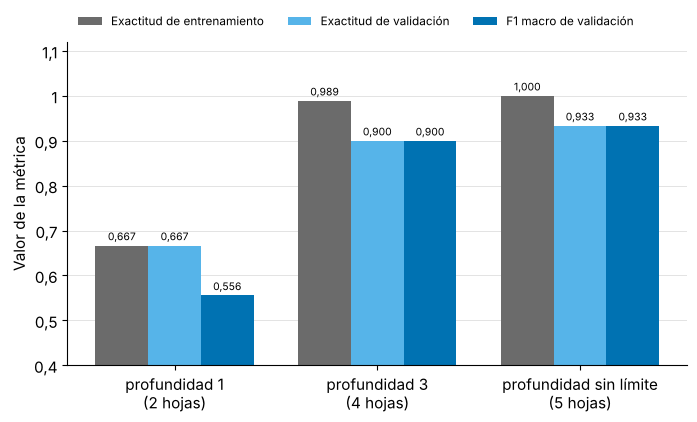

In [23]:
fig, ax = plt.subplots(figsize=(8.0, 4.2))
posiciones = np.arange(3)
ancho = 0.26
series = [("exactitud entrenamiento", "Exactitud de entrenamiento", GRIS),
          ("exactitud validación", "Exactitud de validación", "#56B4E9"),
          ("F1 macro validación", "F1 macro de validación", COLOR["A"])]
for k, (col, nombre, color) in enumerate(series):
    valores = tabla_modelos[col].to_numpy()
    barras = ax.bar(posiciones + (k - 1) * ancho, valores, ancho,
                    color=color, label=nombre)
    for barra, valor in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.012,
                num(valor, 3), ha="center", fontsize=7.5)
ax.set_xticks(posiciones)
ax.set_xticklabels([f"profundidad {e}\n({h} hojas)" for e, h in zip(
    tabla_modelos["profundidad máxima"], tabla_modelos["hojas"])])
ax.set_ylim(0.4, 1.12)
ax.set_ylabel("Valor de la métrica")
coma(ax, "y")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=3,
          bbox_to_anchor=(0, 1.12))
guardar("fig_09_iris_candidatos.png")

In [24]:
pred_test = modelo_sel.predict(X_test)
cm_test = confusion_matrix(y_test, pred_test)
print("Matriz de confusión en prueba (filas reales, columnas predichas):")
print(pd.DataFrame(cm_test, index=nombres_clase,
                   columns=nombres_clase).to_string())
print()
print(classification_report(y_test, pred_test, target_names=nombres_clase,
                            zero_division=0, digits=4))
prec, rec, f1c, soporte = precision_recall_fscore_support(
    y_test, pred_test, zero_division=0)
por_clase = pd.DataFrame({
    "especie": nombres_clase, "precisión": prec, "recall": rec,
    "F1": f1c, "soporte": soporte,
})
exactitud_test = accuracy_score(y_test, pred_test)
f1_macro_test = f1_score(y_test, pred_test, average="macro")
print(f"Exactitud en prueba: {num(exactitud_test)}")
print(f"F1 macro en prueba:  {num(f1_macro_test)}")

Matriz de confusión en prueba (filas reales, columnas predichas):
            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           1          9

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

Exactitud en prueba: 0,9333
F1 macro en prueba:  0,9333


In [25]:
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_test)
comparacion_ref = pd.DataFrame({
    "modelo": ["Árbol seleccionado", "Referencia (clase mayoritaria)"],
    "exactitud en prueba": [exactitud_test,
                            accuracy_score(y_test, pred_ref)],
    "F1 macro en prueba": [f1_macro_test,
                           f1_score(y_test, pred_ref, average="macro")],
})
mostrar(comparacion_ref)

                        modelo exactitud en prueba F1 macro en prueba
            Árbol seleccionado              0,9333             0,9333
Referencia (clase mayoritaria)              0,3333             0,1667


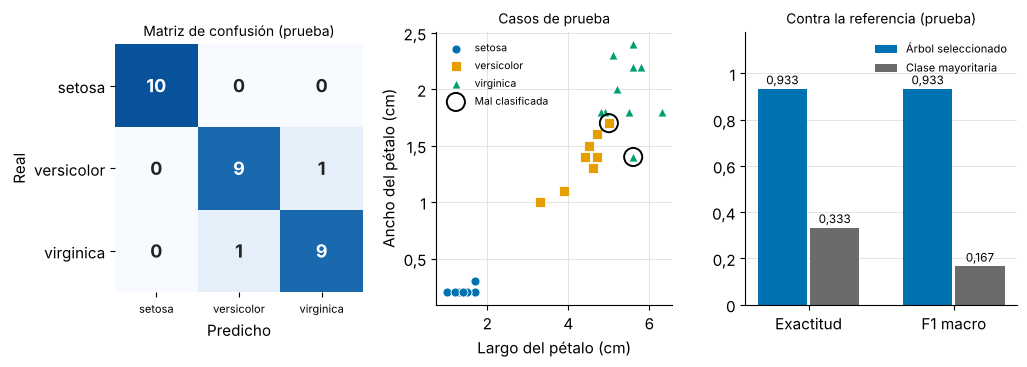

In [26]:
fig, ejes = plt.subplots(1, 3, figsize=(10.4, 3.8),
                         gridspec_kw={"width_ratios": [1.05, 1, 1.15]})
matriz_calor(ejes[0], cm_test, nombres_clase, "Matriz de confusión (prueba)")
ejes[0].tick_params(axis="x", labelsize=8)
ax = ejes[1]
errados = pred_test != y_test.to_numpy()
for i, c in enumerate(nombres_clase):
    sub = X_test[(y_test == i).to_numpy()]
    ax.scatter(sub["petal length (cm)"], sub["petal width (cm)"], s=42,
               c=paleta[i], marker=marcas[i], edgecolor="white",
               linewidth=0.6, label=c, zorder=3)
ax.scatter(X_test[errados]["petal length (cm)"],
           X_test[errados]["petal width (cm)"], s=170, facecolors="none",
           edgecolors="#000000", linewidth=1.4, zorder=4,
           label="Mal clasificada")
ax.set_xlabel("Largo del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.set_title("Casos de prueba", fontsize=10)
ax.legend(frameon=False, fontsize=7.5, loc="upper left")
ax.grid(True, axis="both")
coma(ax)
ax = ejes[2]
nombres_m = ["Exactitud", "F1 macro"]
x0 = np.arange(2)
v_arbol = [exactitud_test, f1_macro_test]
v_ref = [comparacion_ref.iloc[1, 1], comparacion_ref.iloc[1, 2]]
b1 = ax.bar(x0 - 0.18, v_arbol, 0.34, color=COLOR["A"],
            label="Árbol seleccionado")
b2 = ax.bar(x0 + 0.18, v_ref, 0.34, color=GRIS,
            label="Clase mayoritaria")
for barra in list(b1) + list(b2):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.02,
            num(barra.get_height(), 3), ha="center", fontsize=8.5)
ax.set_xticks(x0)
ax.set_xticklabels(nombres_m)
ax.set_ylim(0, 1.18)
ax.set_title("Contra la referencia (prueba)", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right")
coma(ax, "y")
plt.tight_layout()
guardar("fig_10_iris_prueba.png")

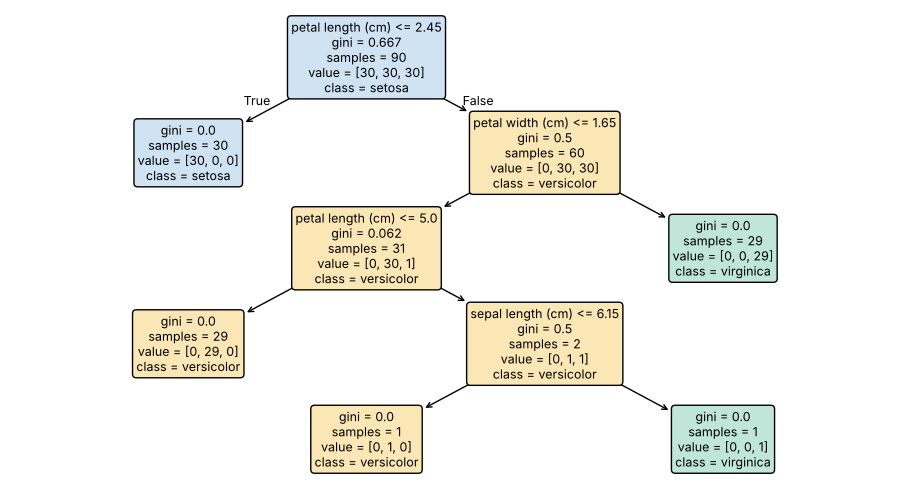

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 5.00
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  5.00
|   |   |   |--- sepal length (cm) <= 6.15
|   |   |   |   |--- class: 1
|   |   |   |--- sepal length (cm) >  6.15
|   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- class: 2



In [27]:
fig, ax = plt.subplots(figsize=(11.5, 6.2))
notas = plot_tree(modelo_sel, feature_names=iris.feature_names,
                  class_names=nombres_clase, filled=True, rounded=True,
                  impurity=True, fontsize=9, ax=ax)
colorear_arbol(notas, dict(zip(nombres_clase,
                               ["#CFE3F2", "#FBE7B5", "#BFE6D9"])))
guardar("fig_11_iris_arbol_seleccionado.png")
print(export_text(modelo_sel, feature_names=list(iris.feature_names)))

### Costo computacional

Se mide el tiempo de ajuste y de predicción (mediana de 200 repeticiones)
y el peso en memoria del modelo serializado con `pickle` para cada uno de
los tres candidatos.

In [28]:
def mediana_ms(funcion, repeticiones=200):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        funcion()
        tiempos.append((time.perf_counter() - inicio) * 1000)
    return float(np.median(tiempos))


filas = []
for profundidad in candidatos:
    etiqueta = "sin límite" if profundidad is None else str(profundidad)

    def ajustar(p=profundidad):
        DecisionTreeClassifier(criterion="gini", max_depth=p,
                               random_state=SEMILLA).fit(X_train, y_train)

    modelo = modelos[etiqueta]
    filas.append({
        "profundidad máxima": etiqueta,
        "ajuste (ms)": mediana_ms(ajustar),
        "predicción en validación (ms)": mediana_ms(
            lambda m=modelo: m.predict(X_val)),
        "peso del modelo (KB)": len(pickle.dumps(modelo)) / 1024,
    })
costos = pd.DataFrame(filas)
mostrar(costos, 3)

profundidad máxima ajuste (ms) predicción en validación (ms) peso del modelo (KB)
                 1       1,487                         0,716                1,537
                 3       1,358                         0,770                1,884
        sin límite       1,346                         0,478                2,055


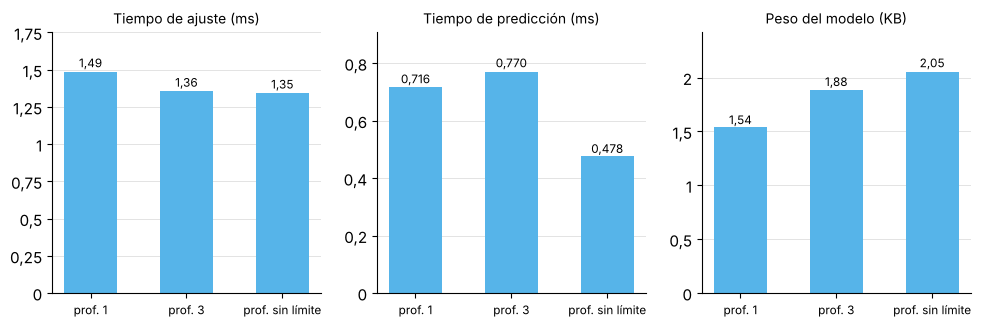

In [29]:
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.4))
etiquetas = [f"prof. {e}" for e in costos["profundidad máxima"]]
for ax, col, titulo, dec in zip(
        ejes, ["ajuste (ms)", "predicción en validación (ms)",
               "peso del modelo (KB)"],
        ["Tiempo de ajuste (ms)", "Tiempo de predicción (ms)",
         "Peso del modelo (KB)"], [2, 3, 2]):
    barras = ax.bar(etiquetas, costos[col], color="#56B4E9", width=0.55)
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2,
                barra.get_height() * 1.02, num(barra.get_height(), dec),
                ha="center", fontsize=8.5)
    ax.set_ylim(0, costos[col].max() * 1.18)
    ax.set_title(titulo, fontsize=10)
    ax.tick_params(axis="x", labelsize=8.5)
    coma(ax, "y")
plt.tight_layout()
guardar("fig_12_costo_computacional.png")